In [139]:
#import sys 

#!{sys.executable} -m pip install pandas numpy matplotlib scikit-learn

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [141]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [142]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [143]:
feature_list = list(df.columns)
print(feature_list)

continuous_feature = ["age", "bmi","HbA1c_level", "blood_glucose_level"]

['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


**Data Checking**

Checking how many types of countable values are in different feature.

If a feature is obvious remove it

In [ ]:
value_types = {}

for df_column in [x for x in feature_list if x not in continuous_feature]:
  value_types[df_column] = {}
  for elem in df[df_column]:
    if elem in value_types[df_column]:
      value_types[df_column][elem] += 1
    else:
      value_types[df_column][elem] = 1

value_types

{'gender': {'Female': 58552, 'Male': 41430, 'Other': 18},
 'hypertension': {0: 92515, 1: 7485},
 'heart_disease': {1: 3942, 0: 96058},
 'smoking_history': {'never': 35095,
  'No Info': 35816,
  'current': 9286,
  'former': 9352,
  'ever': 4004,
  'not current': 6447},
 'diabetes': {0: 91500, 1: 8500}}

**Converting gender to numerical data**

In [ ]:
#Females = 0 , Male = 1, Other = 2
mapping = {"Female": 0, "Male": 1, "Other": 2}
df["gender"] = df["gender"].map(mapping)




df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,never,25.19,6.6,140,0
1,0,54.0,0,0,No Info,27.32,6.6,80,0
2,1,28.0,0,0,never,27.32,5.7,158,0
3,0,36.0,0,0,current,23.45,5.0,155,0
4,1,76.0,1,1,current,20.14,4.8,155,0


In [146]:
df["gender"].isna().sum()

np.int64(0)

**Age Distribution**

Text(0.5, 1.0, 'Age distribution')

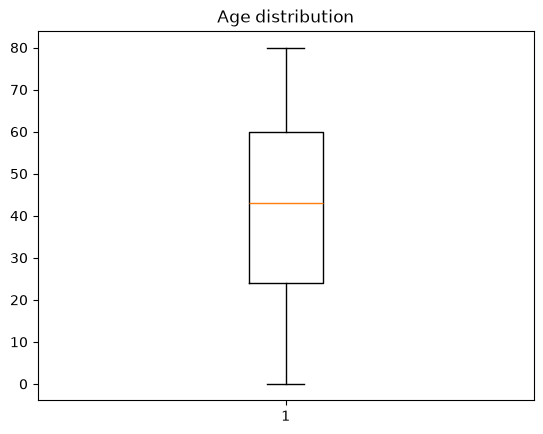

In [ ]:
plt.boxplot(df["age"])
plt.title("Age distribution")

**Bmi Distribution**


Text(0.5, 1.0, 'Bmi distribution')

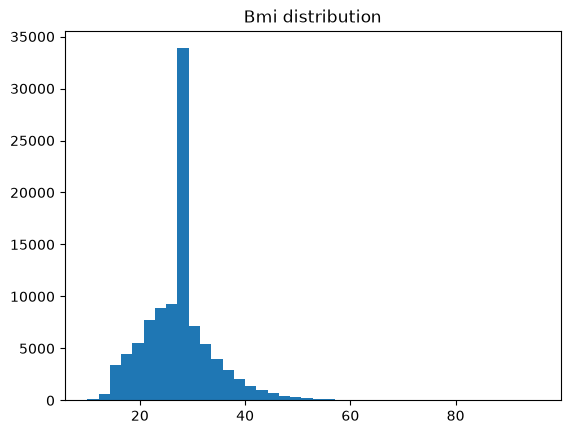

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))


plt.hist(df["bmi"], bins = 40)
plt.title("Bmi distribution")

Text(0.5, 1.0, 'Bmi boxplot to see outliers')

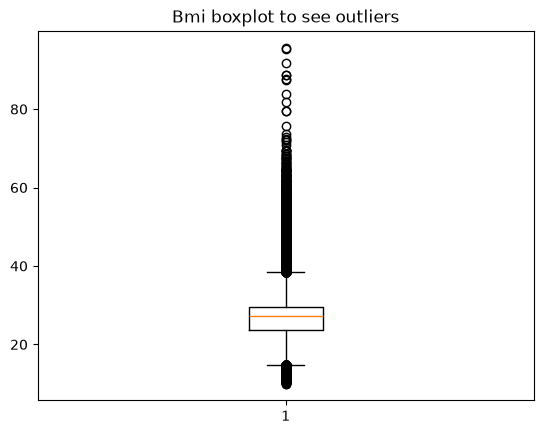

In [174]:
plt.boxplot(df["bmi"])
plt.title("Bmi boxplot to see outliers")

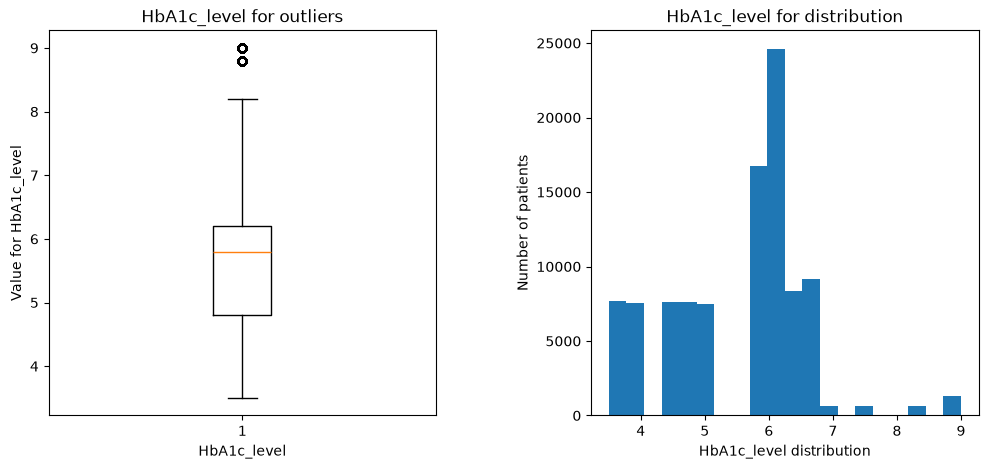

In [182]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.boxplot(df["HbA1c_level"])
ax1.set_title("HbA1c_level for outliers")
ax1.set_xlabel("HbA1c_level")
ax1.set_ylabel("Value for HbA1c_level")

ax2.hist(df["HbA1c_level"], bins = 20)
ax2.set_title("HbA1c_level for distribution")
ax2.set_xlabel("HbA1c_level distribution")
ax2.set_ylabel("Number of patients")

plt.subplots_adjust(wspace=0.4)